# KratTrade: Hybrid Energy Portfolio Optimisation
## Toy example
A four-hour example with a battery, a solar asset and two markets, followed by a six-variable QUBO and a QAOA experiment.


## S01 — Selected problem and proposed toy example
### Selected problem (from the company application)
> Batteries, solar and wind parks and demand response are managed as one portfolio. For every hour, we need to decide which asset to offer to which market, taking into account weather forecast uncertainty and imbalance costs. The number of possible combinations grows quickly as more assets are added.

### Proposed toy example
Select one four-hour battery schedule and one solar-backed energy sales commitment. Evaluate their combined expected profit under two solar production scenarios.

Compare the exact best plan pair with QAOA results in simulation and on IBM Quantum and IQM.


## S02 — Terms
| Term | Meaning here |
|---|---|
| MW | Power: the rate of charging, discharging or reserved response. |
| MWh | Energy; 1 MW sustained for one hour is 1 MWh. |
| Reserve capacity | Power held available for a possible request from the grid operator. |
| Imbalance shortfall | Committed energy that the portfolio does not deliver. |
| Scenario | One possible solar production trajectory over the same four hours. |
| QUBO | A quadratic cost function of binary variables. |
| QAOA | A parameterised quantum circuit whose angles are adjusted by a classical optimiser. |


## S03 — Toy-model assumptions
- One battery, one solar asset and four one-hour periods.
- Two revenue sources: energy sales and upward reserve capacity.
- Two solar scenarios, each with probability 0.5.
- All sales commitments, charging, discharging and reserve schedules are fixed before solar production is known. The same schedules apply in both scenarios.
- Grid charging is allowed at the tabulated energy price. Charging purchases are scheduled and settled separately from the sales commitment.
- Solar production and scheduled battery discharge jointly meet the energy sales commitment. Any surplus is settled at 50% of the tabulated energy price; any shortfall costs 150 EUR/MWh. Advance commitments therefore offer a better price than surplus settlement but expose the portfolio to shortfall costs.
- Reserve bids are accepted at the tabulated capacity price. Reserved power cannot also be used for scheduled discharge.
- This is a **capacity-only reserve example**: no reserve activation occurs in the evaluated scenarios. Each reserve commitment must nevertheless be deliverable for a 15-minute upward response.
- Use a conservative battery deliverability test: enough energy must be available at both the start and end of each hour to support its reserved power for 15 minutes. Each hour is checked independently, not as a sequence of reserve activations.
- No degradation charges, network fees or shared grid export limit. Simultaneous battery charging and discharging is excluded. Battery energy must return to 1 MWh at the end of the horizon.

These assumptions define the calculations below; no additional market rules are needed for this example.


## S04 — Synthetic input data
All figures are illustrative, not market observations. The energy price is used for advance sales and scheduled charging purchases. Surplus energy is settled at half that price; this discount is a toy assumption, not a description of Baltic market settlement.

| Hour | Energy price (EUR/MWh) | Reserve price (EUR/MW/hour) | Solar: expected (MWh) | Solar: low (MWh) | Shortfall cost (EUR/MWh) |
|---|---:|---:|---:|---:|---:|
| 12–13 | 40 | 10 | 2 | 1 | 150 |
| 13–14 | 30 | 15 | 3 | 1.5 | 150 |
| 14–15 | 70 | 25 | 2 | 1 | 150 |
| 15–16 | 90 | 40 | 1 | 0.5 | 150 |

| Battery parameter | Value |
|---|---:|
| Energy capacity | 2 MWh |
| Initial and terminal energy | 1 MWh |
| Maximum charge / discharge power | 1 MW / 1 MW |
| Charge / discharge efficiency | 0.95 / 0.95 |
| Reserve response duration | 0.25 hours |


## S05 — Numeric candidate plans and profit calculation
Each vector contains one value for each of the four hours.

### Battery candidates
| Candidate | Charge (MW) | Discharge (MW) | Upward reserve (MW) |
|---|---|---|---|
| B1 | [0.5, 0, 0, 0] | [0, 0, 0, 0.45125] | [0, 0, 0, 0] |
| B2 | [0, 0, 0, 0] | [0, 0, 0, 0] | [0.5, 0.5, 0.5, 0.5] |
| B3 | [0.25, 0, 0, 0] | [0, 0, 0.225625, 0] | [0.25, 0.25, 0.25, 0.25] |

The discharge amounts account for both charging and discharging losses and return the battery to its initial energy.

### Solar-backed sales commitments
| Candidate | Committed energy (MWh) |
|---|---|
| G1 | [2, 3, 2, 1] |
| G2 | [1, 1.5, 1, 0.5] |
| G3 | [1, 1.5, 1, 1] |

These are portfolio energy commitments: battery discharge can cover a solar shortfall. Its remaining discharge is sold as surplus; do not also count it as a separate sale.

### Worked example: B2 + G2
B2 holds 0.5 MW of reserve in every hour, with no charging or discharging. G2 commits [1, 1.5, 1, 0.5] MWh to energy sales.

In the first hour, the committed sale earns 1 MWh x 40 EUR/MWh = 40 EUR, and the reserve earns 0.5 MW x 10 EUR/MW/hour x 1 hour = 5 EUR.
- Expected solar scenario: production is 2 MWh. The extra 1 MWh earns 20 EUR at the surplus price, giving 65 EUR in total.
- Low solar scenario: production is 1 MWh. It exactly meets the commitment, giving 45 EUR in total.
- With equal scenario probabilities, expected profit for this hour is (65 + 45) / 2 = 55 EUR.

Repeating the same calculation for all four hours:

| Hour | Expected solar scenario profit (EUR) | Low solar scenario profit (EUR) | Probability-weighted profit (EUR) |
|---|---:|---:|---:|
| 12-13 | 65 | 45 | 55 |
| 13-14 | 75 | 52.5 | 63.75 |
| 14-15 | 117.5 | 82.5 | 100 |
| 15-16 | 87.5 | 65 | 76.25 |
| **Four-hour total** | **345** | **245** | **295** |

There are no shortfalls, charging purchases or reserve activations for this pair. The 295 EUR is its expected four-hour profit, not a third scenario. Comparing all nine pairs establishes that B2 + G2 is the best pair in this candidate library (S07).

The following equations express the feasibility checks and profit calculation for any candidate pair.

### Feasibility
For hour $t$, charge $c_t$, discharge $d_t$, reserve $r_t$, and end-of-hour battery energy $e_t$:
$$
e_t=e_{t-1}+0.95c_t\Delta t-\frac{d_t\Delta t}{0.95},\qquad \Delta t=1\text{ hour}.
$$
Check $0\le e_t\le2$, $0\le c_t,d_t\le1$, $c_td_t=0$, $d_t+r_t\le1$, and $e_4=1$.
For the conservative reserve test:
$$
\min(e_{t-1},e_t)\ge\frac{0.25r_t}{0.95},\qquad r_t\ge0.
$$
The listed schedules satisfy these checks. Their charging hours have zero scheduled discharge; the conservative reserve rule does not credit stopping charge as additional reserve capability.

### Scenario profit
For selected battery plan $i$, sales plan $j$, scenario $s$, solar energy $a_{t,s}$, and commitment $q_{j,t}$, define delivered energy before shortfall settlement:
$$
y_{i,t,s}=a_{t,s}+d_{i,t}\Delta t.
$$
With advance-sale and charging price $p_t$, surplus settlement price $u_t=0.5p_t$, reserve price $v_t$, and shortfall rate $k_t=150$:
$$
\Pi_{ij,s}=\sum_t\left[
p_tq_{j,t}
+u_t\max(y_{i,t,s}-q_{j,t},0)
-k_t\max(q_{j,t}-y_{i,t,s},0)
-p_tc_{i,t}\Delta t
+v_tr_{i,t}\Delta t
\right].
$$
Compute expected profit as $\bar\Pi_{ij}=0.5\Pi_{ij,\mathrm{expected}}+0.5\Pi_{ij,\mathrm{low}}$.
The maximum terms are evaluated classically for each plan pair before constructing the QUBO.


## S06 — Six-variable QUBO
Assign one binary variable to each candidate:
$$
b_1,b_2,b_3,g_1,g_2,g_3\in\{0,1\}.
$$
Exactly one battery plan and one sales plan must be selected.
With $C_{ij}=-\bar\Pi_{ij}$, minimise
$$
E(b,g)=\sum_{i,j}C_{ij}b_ig_j+
\lambda\left(\sum_i b_i-1\right)^2+
\lambda\left(\sum_j g_j-1\right)^2.
$$
Expanding the squares produces only constant, linear and quadratic terms because $x^2=x$ for binary variables.

For this example, choose $\lambda=1+\sum_{i,j}|C_{ij}|$, with the constant 1 expressed in the same numerical cost units. Every invalid bitstring incurs at least one penalty. The bound makes invalid states more expensive than the valid optimum. Smaller penalties may be tested after checking the full energy landscape.

Verify all 64 bitstrings against the nine valid plan pairs. Keep the constant offset when comparing QUBO energy to economic cost.

**Circuit size:** Six logical qubits, no slack variables. Nine bitstrings satisfy the two one-hot constraints. The quantum solver searches the fixed candidate library, not all possible continuous schedules.


## S07 — Exact classical reference
1. Evaluate the two-scenario profit of each of the nine plan pairs.
2. Select the pair with the highest expected profit.
3. Enumerate all 64 QUBO bitstrings and confirm that its minimum corresponds to an optimal valid pair.
4. Check decoding, constraint violations, signs and constant offsets.

Report the optimal expected profit and all tied optimal pairs. This is the exact reference **within the specified candidate library**.

The classical angle optimiser used by QAOA is a separate component: it adjusts circuit parameters rather than providing this reference solution.

### Verified reference values (EUR)
| Battery plan | G1 | G2 | G3 |
|---|---:|---:|---:|
| B1 | 123.996875 | 250.306250 | 270.246875 |
| B2 | 145.000000 | 295.000000 | 291.250000 |
| B3 | 133.370313 | 270.396875 | 266.646875 |

The exact best pair is B2 + G2, with expected profit 295.000000 EUR. All 64 QUBO bitstrings were checked against this reference. These values are classical arithmetic checks, not QAOA results.


## S08 — From QUBO to a QAOA circuit
Once the binary variables and QUBO coefficients are defined, Qiskit can construct the cost operator and parameterised QAOA circuit using standard tools. You do not need to write the individual quantum gates by hand to build this example.

### Model first, circuit second
QUBO is a mathematical model, not a quantum algorithm. It expresses a cost using binary variables, linear terms and pairwise products. QAOA is one method for searching for low-cost assignments.

In this example, we compute all nine plan-pair profits before constructing the QUBO. That table already makes the classical optimum easy to find. This is an introductory circuit and modelling exercise.

For a larger problem, define variables, economic costs and operational constraints directly where possible, rather than enumerating every complete solution. Derive and validate the QUBO from those rules; choosing a cost function is not simply trying arbitrary formulas until one produces attractive results. Discretisation, penalty weights and additional variables may be needed.

### What the circuit does
- Prepare an equal superposition of the 64 six-bit assignments. Only nine obey our selection rules.
- Apply a **cost layer**: each assignment receives a phase determined by its cost and an angle $\gamma$. This does not output a numerical cost or, on its own, change measurement probabilities.
- Apply a **mixer layer**, controlled by $\beta$. Together with the cost phases, it creates interference that changes the probabilities of measuring assignments.
- Repeat this pair of layers $p$ times, then measure. A measured bitstring specifies which plans were selected; its cost is evaluated classically.

For standard QAOA, $p=1$ has two adjustable angles, one $\gamma$ and one $\beta$, shared across the corresponding layers. $p=2$ has four angles. We choose $p$; the classical optimiser adjusts the angles. Layer count is different from both compiled gate depth and the number of measurement repetitions.

The cost function is therefore used both to construct the circuit and to score its measured outputs. The aim is to obtain good valid assignments more frequently; finding the exact optimum is not guaranteed.


### Classical optimisation with COBYLA
**COBYLA is a classical, derivative-free optimiser.** It uses evaluated objective values to propose new circuit angles. It runs outside the quantum circuit; it is not an intermediate quantum measurement or another quantum layer.

A typical loop is:
1. Choose an initial set of angles.
2. Execute the circuit many times at those same angles, for example 1,000 shots.
3. Calculate the QUBO cost of each measured bitstring, including penalties, and average the costs.
4. Return the average to COBYLA, which proposes another set of angles.
5. Repeat until the chosen stopping criterion or evaluation budget is reached.

One submission can request many shots. New angle evaluations generally require further execution requests. A provider session can reduce scheduling overhead where available, but the optimiser remains classical.

Start with $p=1$ and compare with $p=2$, using several initial angle settings. More layers can increase expressive power but also gate count, noise and optimisation effort.

### Minimal Qiskit circuit example
The next cell encodes the expanded QUBO and builds a six-qubit, one-layer QAOA circuit. The profit table comes from S07. Run the short setup cell first in Google Colab. It installs Qiskit and Qiskit Optimization only if the required imports fail. The following cell builds the circuit.

**This cell only constructs the circuit.** It does not run COBYLA, sample a simulator, submit a hardware job or solve the optimisation problem. Those steps remain in the S09 implementation cells.

For IBM–IQM tests, keep the logical objective identical and compile separately for each device. Compare fixed simulator-trained angles first; report any hardware-in-the-loop training separately. Record shots, all optimiser evaluations, initialisations, compiled depth, two-qubit gate count and total execution cost.


In [1]:
# Run this cell before the Qiskit example in Google Colab.
try:
    from qiskit_optimization import QuadraticProgram
    from qiskit.circuit.library import QAOAAnsatz
except ImportError:
    %pip install -q "qiskit>=2,<3" "qiskit-optimization>=0.7,<0.8"
    from qiskit_optimization import QuadraticProgram
    from qiskit.circuit.library import QAOAAnsatz

print("Qiskit is ready.")


Qiskit is ready.


In [2]:
import numpy as np
from itertools import combinations
from qiskit_optimization import QuadraticProgram
from qiskit.circuit.library import QAOAAnsatz

# Rows: B1, B2, B3. Columns: G1, G2, G3.
profit = np.array([
    [123.996875, 250.306250, 270.246875],
    [145.000000, 295.000000, 291.250000],
    [133.3703125, 270.396875, 266.646875],
])
C = -profit
penalty = 1.0 + np.abs(C).sum()

qubo = QuadraticProgram("KratTrade")
B = ["b1", "b2", "b3"]
G = ["g1", "g2", "g3"]
for name in B + G:
    qubo.binary_var(name)

# For binary variables, expanding lambda * (sum(x) - 1)**2
# gives constant lambda, linear terms -lambda,
# and pairwise terms 2*lambda within each group.
linear = {name: -penalty for name in B + G}
quadratic = {
    (B[i], G[j]): float(C[i, j])
    for i in range(3)
    for j in range(3)
}
for group in [B, G]:
    for x, y in combinations(group, 2):
        quadratic[(x, y)] = 2 * penalty

qubo.minimize(
    constant=2 * penalty,
    linear=linear,
    quadratic=quadratic,
)

# Verify that the expanded objective matches S06 for all 64 states.
from itertools import product

for bits in product([0, 1], repeat=6):
    expected_cost = (
        sum(C[i, j] * bits[i] * bits[j + 3]
            for i in range(3) for j in range(3))
        + penalty * (sum(bits[:3]) - 1)**2
        + penalty * (sum(bits[3:]) - 1)**2
    )
    assert np.isclose(qubo.objective.evaluate(list(bits)), expected_cost)

cost_operator, offset = qubo.to_ising()
circuit = QAOAAnsatz(
    cost_operator=cost_operator,
    reps=1,
    flatten=True,
)

assert circuit.num_qubits == 6
assert circuit.num_parameters == 2
print("Qubits:", circuit.num_qubits)
print("Adjustable angles:", circuit.num_parameters)
print(circuit.decompose().draw(output="text"))

# offset is a constant energy shift. Keep it when comparing absolute
# objective values; it does not change which bitstring is optimal.
# This is an unmeasured circuit template, not an execution or optimiser loop.


Qubits: 6
Adjustable angles: 2
global phase: 5118.535156250001*γ[0]
     ┌────────────┐┌───────────────────────────────┐     »
q_0: ┤ U(π/2,0,π) ├┤ P((-1724.9390625000003)*γ[0]) ├──■──»
     ├────────────┤├───────────────────────────────┤┌─┴─┐»
q_1: ┤ U(π/2,0,π) ├┤ P((-1681.5890625000002)*γ[0]) ├┤ X ├»
     ├────────────┤├───────────────────────────────┤└───┘»
q_2: ┤ U(π/2,0,π) ├┤ P((-1712.0070312500002)*γ[0]) ├─────»
     ├────────────┤├───────────────────────────────┤     »
q_3: ┤ U(π/2,0,π) ├┤ P((-1846.0304687500002)*γ[0]) ├─────»
     ├────────────┤├───────────────────────────────┤     »
q_4: ┤ U(π/2,0,π) ├┤ P((-1639.3625000000002)*γ[0]) ├─────»
     ├────────────┤└──┬─────────────────────────┬──┘     »
q_5: ┤ U(π/2,0,π) ├───┤ P((-1633.1421875)*γ[0]) ├────────»
     └────────────┘   └─────────────────────────┘        »
«                                                                             »
«q_0: ─────────────────────────────────■────■─────────────────────────────────»
«    

## S09 — Implementation
The following cells organise the calculations and experiments.


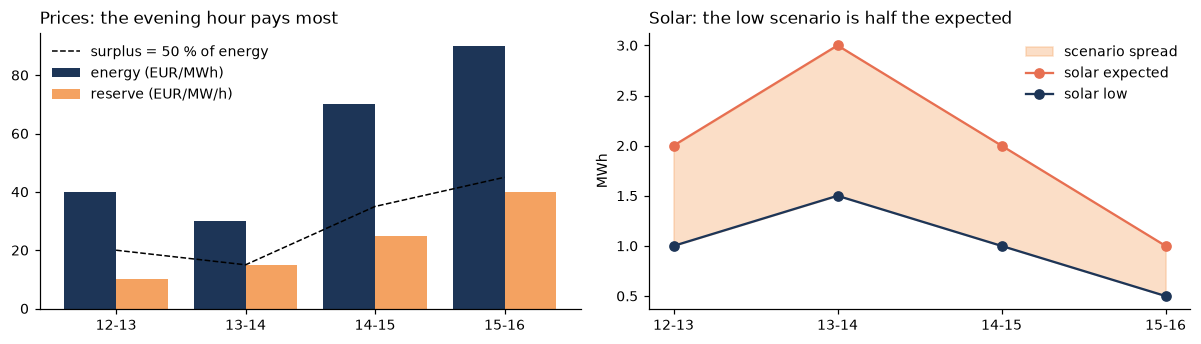

In [3]:
# S04 data and battery parameters, as tabulated (EUR, MW, MWh; four one-hour periods)
import sys, time, json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, str(pathlib.Path.cwd())); sys.path.insert(0, str(pathlib.Path.cwd().parent))
import makkah_qopt as K   # our solver library (notebooks/makkah_qopt.py): QUBO helpers + 14 classical / quantum / hybrid methods

HOURS = ['12-13', '13-14', '14-15', '15-16']; DT = 1.0
price   = np.array([40, 30, 70, 90.])     # EUR/MWh: advance sales and scheduled charging
reserve = np.array([10, 15, 25, 40.])     # EUR/MW/hour: upward reserve capacity
solar   = {'expected': np.array([2, 3, 2, 1.]), 'low': np.array([1, 1.5, 1, .5])}   # MWh, probability 0.5 each
SHORT   = 150.0                            # EUR/MWh shortfall
CAP, E0, PMAX, ETA, RESP = 2.0, 1.0, 1.0, .95, .25   # MWh, MWh, MW, charge = discharge efficiency, h of reserve response

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
NAVY, CORAL, CYAN, GREEN, PEACH, GREY = '#1d3557', '#e76f51', '#2a9d8f', '#8ab17d', '#f4a261', '#9aa0a6'
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
x = np.arange(4); ax[0].bar(x - .2, price, .4, color=NAVY, label='energy (EUR/MWh)'); ax[0].bar(x + .2, reserve, .4, color=PEACH, label='reserve (EUR/MW/h)')
ax[0].plot(x, price / 2, 'k--', lw=1, label='surplus = 50 % of energy'); ax[0].set_xticks(x, HOURS); ax[0].legend(frameon=False); ax[0].set_title('Prices: the evening hour pays most', loc='left')
ax[1].fill_between(x, solar['low'], solar['expected'], color=PEACH, alpha=.35, label='scenario spread')
for k, c in (('expected', CORAL), ('low', NAVY)): ax[1].plot(x, solar[k], 'o-', color=c, label=f'solar {k}')
ax[1].set_xticks(x, HOURS); ax[1].set_ylabel('MWh'); ax[1].legend(frameon=False); ax[1].set_title('Solar: the low scenario is half the expected', loc='left')
plt.tight_layout(); plt.show()

every battery plan passes all six checks; best pair B2 + G2: 295.000000 EUR (S07 verified)


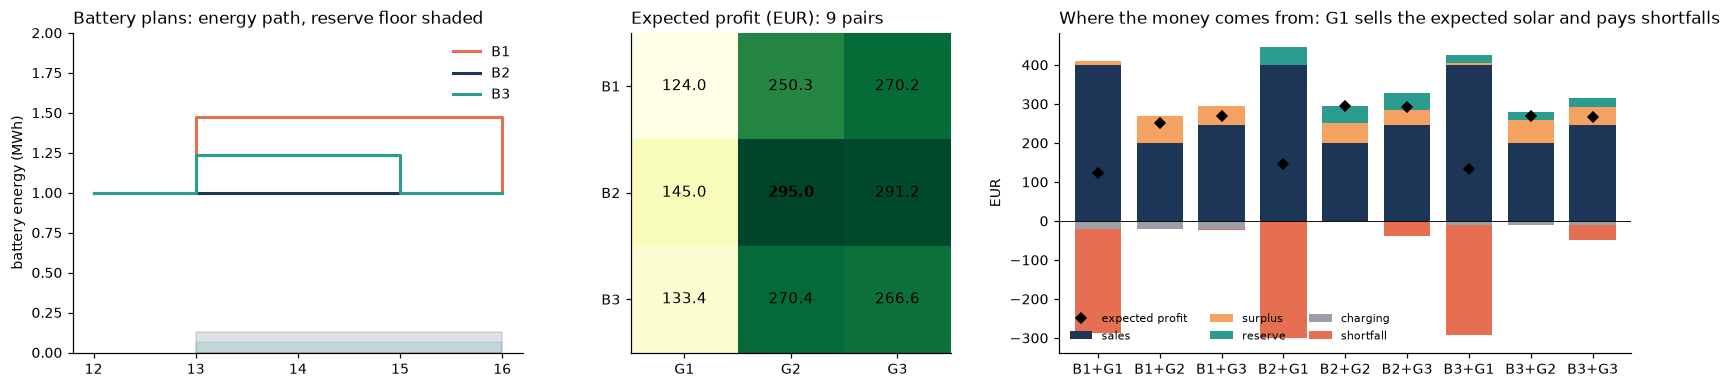

In [4]:
# S05 candidates, feasibility checks and the 3 x 3 expected-profit table (the S05 formula, term by term)
BAT = {'B1': dict(c=[.5, 0, 0, 0], d=[0, 0, 0, .45125], r=[0, 0, 0, 0]),
       'B2': dict(c=[0, 0, 0, 0], d=[0, 0, 0, 0], r=[.5, .5, .5, .5]),
       'B3': dict(c=[.25, 0, 0, 0], d=[0, 0, .225625, 0], r=[.25, .25, .25, .25])}
SALES = {'G1': [2, 3, 2, 1], 'G2': [1, 1.5, 1, .5], 'G3': [1, 1.5, 1, 1]}
BAT = {k: {n: np.array(v, float) for n, v in b.items()} for k, b in BAT.items()}; SALES = {k: np.array(v, float) for k, v in SALES.items()}

def soc(b):  # end-of-hour energy e_t
    return E0 + np.cumsum(ETA * b['c'] * DT - b['d'] * DT / ETA)

def feasible(b):
    e = soc(b); prev = np.r_[E0, e[:-1]]
    checks = {'0 <= e <= 2': (e >= -1e-9).all() and (e <= CAP + 1e-9).all(), 'c, d within 1 MW': (b['c'] <= PMAX).all() and (b['d'] <= PMAX).all(),
              'no charge + discharge': not (b['c'] * b['d']).any(), 'd + r <= 1': (b['d'] + b['r'] <= PMAX + 1e-9).all(),
              'e_4 = 1': abs(e[-1] - E0) < 1e-9, '15-min reserve': (np.minimum(prev, e) >= RESP * b['r'] / ETA - 1e-9).all()}
    return checks

def parts(b, q, a):  # EUR per hour for one scenario: sales, surplus, shortfall, charging, reserve
    y = a + b['d'] * DT
    return dict(sales=price * q, surplus=.5 * price * np.maximum(y - q, 0), shortfall=-SHORT * np.maximum(q - y, 0), charging=-price * b['c'] * DT, reserve=reserve * b['r'] * DT)

def scen_profit(b, q, a): return sum(v.sum() for v in parts(b, q, a).values())   # Pi_ij,s

for k, b in BAT.items(): assert all(feasible(b).values()), (k, feasible(b))
profit_tab = np.array([[.5 * scen_profit(BAT[i], SALES[j], solar['expected']) + .5 * scen_profit(BAT[i], SALES[j], solar['low']) for j in SALES] for i in BAT])
VERIFIED = np.array([[123.996875, 250.306250, 270.246875], [145., 295., 291.25], [133.3703125, 270.396875, 266.646875]])
assert np.allclose(profit_tab, VERIFIED) and np.allclose(profit_tab, profit)   # = S07's verified table = the circuit cell's `profit`
wk = {s: sum(parts(BAT['B2'], SALES['G2'], solar[s]).values()) for s in solar}   # S05 worked example, B2 + G2
assert np.allclose(wk['expected'], [65, 75, 117.5, 87.5]) and np.allclose(wk['low'], [45, 52.5, 82.5, 65])
bi, bj = np.unravel_index(profit_tab.argmax(), profit_tab.shape); BEST = profit_tab.max()
print(f"every battery plan passes all six checks; best pair B{bi + 1} + G{bj + 1}: {BEST:.6f} EUR (S07 verified)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[1.1, .9, 1.4]))
for (k, b), c in zip(BAT.items(), (CORAL, NAVY, CYAN)):
    e = np.r_[E0, soc(b)]; ax[0].step(range(5), e, where='post', color=c, lw=2, label=k)
    ax[0].fill_between(range(1, 5), RESP * b['r'] / ETA, 0, step='pre', color=c, alpha=.15)
ax[0].set_xticks(range(5), ['12', '13', '14', '15', '16']); ax[0].set_ylim(0, CAP); ax[0].set_ylabel('battery energy (MWh)'); ax[0].legend(frameon=False)
ax[0].set_title('Battery plans: energy path, reserve floor shaded', loc='left')
im = ax[1].imshow(profit_tab, cmap='YlGn'); ax[1].set_xticks(range(3), SALES); ax[1].set_yticks(range(3), BAT)
for i in range(3):
    for j in range(3): ax[1].text(j, i, f'{profit_tab[i, j]:.1f}', ha='center', va='center', fontsize=10, weight='bold' if (i, j) == (bi, bj) else None)
ax[1].set_title('Expected profit (EUR): 9 pairs', loc='left')
comp = {f'B{i + 1}+G{j + 1}': {k: .5 * (parts(BAT[f'B{i + 1}'], SALES[f'G{j + 1}'], solar['expected'])[k] + parts(BAT[f'B{i + 1}'], SALES[f'G{j + 1}'], solar['low'])[k]).sum()
        for k in ('sales', 'surplus', 'reserve', 'charging', 'shortfall')} for i in range(3) for j in range(3)}
D = pd.DataFrame(comp).T; cols = dict(sales=NAVY, surplus=PEACH, reserve=CYAN, charging=GREY, shortfall=CORAL)
D.plot.bar(stacked=True, ax=ax[2], color=[cols[c] for c in D.columns], width=.75); ax[2].plot(range(9), D.sum(1), 'kD', ms=5, label='expected profit')
ax[2].axhline(0, color='k', lw=.6); ax[2].tick_params(axis='x', rotation=0); ax[2].legend(frameon=False, ncol=3, fontsize=7.5); ax[2].set_ylabel('EUR')
ax[2].set_title('Where the money comes from: G1 sells the expected solar and pays shortfalls', loc='left'); plt.tight_layout(); plt.show()

lambda = 2047.21; 9 valid states from -295.0 to -124.0; cheapest invalid 1461.0; optimum 010010 = B2 + G2


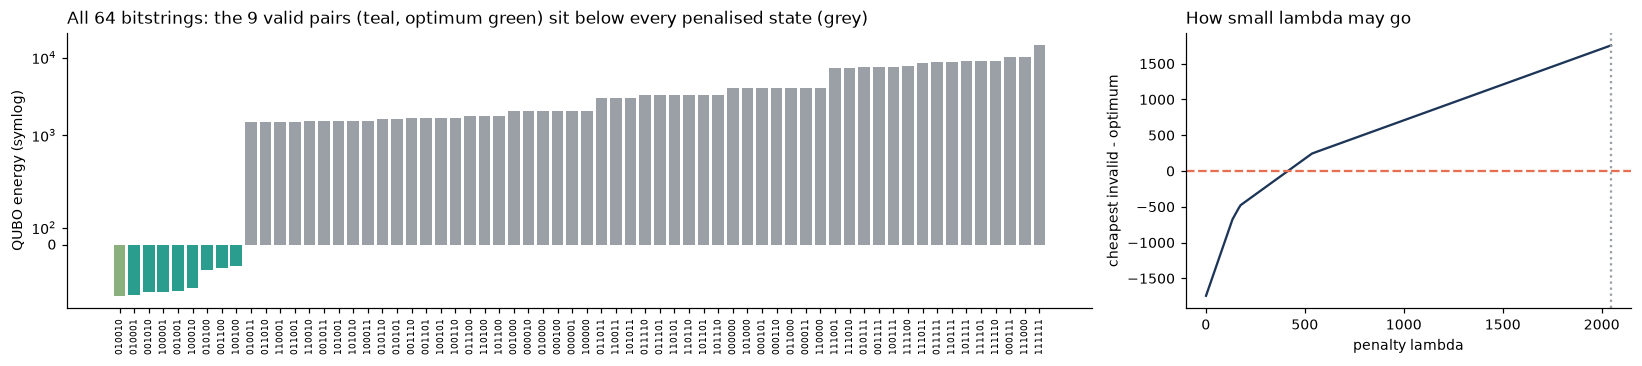

smallest lambda keeping the optimum valid: 422.6 (the starter's bound is 2047.2)


In [5]:
# S06 QUBO: lambda = 1 + sum|C|; all 64 bitstrings checked against the starter's QuadraticProgram and the 9 valid pairs
from itertools import product
Q, LAM = K.qubo(profit_tab)                       # (constant, linear, quadratic) in x = (b1, b2, b3, g1, g2, g3)
TERMS, OFF = K.qubo_terms(Q, 6)                   # Pauli-Z form, x_i = (1 - Z_i)/2, qubit i = variable i
X = np.array(list(product([0, 1], repeat=6))); E = np.array([K.qubo_energy(Q, x) for x in X]); ok = lambda x: K.one_hot(x)
VALID = np.array([ok(x) for x in X])
assert np.isclose(LAM, penalty)                                                     # the starter's lambda
assert np.allclose(E, [qubo.objective.evaluate(list(x)) for x in X])                # = the starter's QuadraticProgram, all 64
assert np.allclose(E, K.term_energies(TERMS, OFF, X))                               # = the Ising form the circuits use
for x, e in zip(X[VALID], E[VALID]): i, j = x[:3].argmax(), x[3:].argmax(); assert np.isclose(e, -profit_tab[i, j])  # valid = -profit
assert E[~VALID].min() > E[VALID].max(); OPT = E.min(); assert np.isclose(-OPT, BEST)
T0, O0 = K.qubo_terms(K.qubo(profit_tab, 0.0)[0], 6); GROUPS = [(0, 1, 2), (3, 4, 5)]   # objective-only terms (XY mixer keeps one-hot)
lab = lambda x: ''.join(map(str, x)); o = np.argsort(E)
print(f"lambda = {LAM:.2f}; 9 valid states from {E[VALID].min():.1f} to {E[VALID].max():.1f}; cheapest invalid {E[~VALID].min():.1f}; optimum {lab(X[E.argmin()])} = B2 + G2")
fig, ax = plt.subplots(1, 2, figsize=(15, 3.4), gridspec_kw=dict(width_ratios=[2.3, 1]))
ax[0].bar(range(64), E[o], color=[(GREEN if np.isclose(E[k], OPT) else CYAN) if VALID[k] else GREY for k in o]); ax[0].set_yscale('symlog', linthresh=500)
ax[0].set_xticks(range(64), [lab(X[k]) for k in o], rotation=90, fontsize=6); ax[0].set_ylabel('QUBO energy (symlog)')
ax[0].set_title('All 64 bitstrings: the 9 valid pairs (teal, optimum green) sit below every penalised state (grey)', loc='left')
lams = np.linspace(1, LAM, 200); gap = [min(K.qubo_energy(K.qubo(profit_tab, l)[0], x) for x in X[~VALID]) - OPT for l in lams]
ax[1].plot(lams, gap, color=NAVY); ax[1].axhline(0, color=CORAL, ls='--'); ax[1].axvline(LAM, color=GREY, ls=':'); ax[1].set_xlabel('penalty lambda')
ax[1].set_ylabel('cheapest invalid - optimum'); ax[1].set_title('How small lambda may go', loc='left'); plt.tight_layout(); plt.show()
print(f"smallest lambda keeping the optimum valid: {lams[np.argmax(np.array(gap) > 0)]:.1f} (the starter's bound is {LAM:.1f})")

p=1: optimal-pair frequency per start [np.float64(0.04), np.float64(0.046), np.float64(0.007)] | valid [np.float64(0.391), np.float64(0.461), np.float64(0.069)]


p=2: optimal-pair frequency per start [np.float64(0.036), np.float64(0.024), np.float64(0.037)] | valid [np.float64(0.335), np.float64(0.26), np.float64(0.27)]


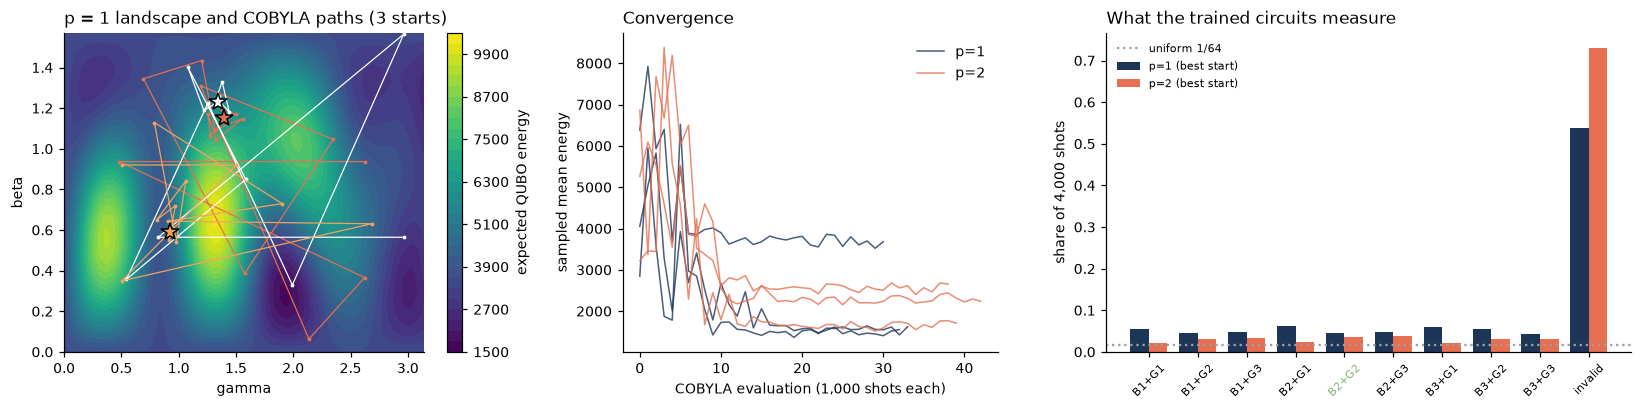

In [6]:
# Simulator QAOA with COBYLA, p = 1 and p = 2, three starting angles each; every sample decoded and priced
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit import transpile
from scipy.optimize import minimize
SCALE = max(abs(c) for c in cost_operator.coeffs); H = cost_operator / SCALE      # the starter's operator, scaled to |coef| <= 1
sim = AerSimulator(); SHOTS = 1000
def decode(counts):  # bitstring (qubit 0 rightmost) -> x, the priced sample table
    xs = np.array([[int(k[5 - i]) for i in range(6)] for k in counts]); w = np.array(list(counts.values()), float)
    e = K.term_energies(TERMS, OFF, xs); v = np.array([ok(x) for x in xs]); hit = np.isclose(e, OPT)
    return dict(x=xs, w=w, e=e, valid=w[v].sum() / w.sum(), opt=w[hit].sum() / w.sum(), best=-e[v].min() if v.any() else np.nan, mean=(e * w).sum() / w.sum())
def angles(ans, th):
    p = len(th) // 2; g = sorted([q for q in ans.parameters if q.name.startswith('γ')], key=lambda q: q.index); b = sorted([q for q in ans.parameters if q.name.startswith('β')], key=lambda q: q.index)
    return {**dict(zip(g, th[:p])), **dict(zip(b, th[p:]))}
RUNS = {}
for p in (1, 2):
    ans = QAOAAnsatz(H, reps=p); ans.measure_all(); base = transpile(ans, sim)
    for init in range(3):
        rng = np.random.default_rng(100 * p + init); hist = []; t0 = time.time()
        def f(th):
            d = decode(sim.run(base.assign_parameters(angles(base, th)), shots=SHOTS, seed_simulator=len(hist) + 1).result().get_counts()); hist.append((th.copy(), d['mean'])); return d['mean']
        r = minimize(f, np.r_[rng.uniform(0, np.pi, p), rng.uniform(0, np.pi / 2, p)], method='COBYLA', options=dict(maxiter=60))
        fin = decode(sim.run(base.assign_parameters(angles(base, r.x)), shots=4 * SHOTS, seed_simulator=999).result().get_counts())
        RUNS[(p, init)] = dict(fin, theta=r.x, hist=hist, evals=len(hist), shots=len(hist) * SHOTS + 4 * SHOTS, seconds=time.time() - t0)
    print(f"p={p}: optimal-pair frequency per start", [round(RUNS[(p, i)]['opt'], 3) for i in range(3)], '| valid', [round(RUNS[(p, i)]['valid'], 3) for i in range(3)])
BESTRUN = {p: max(range(3), key=lambda i: (RUNS[(p, i)]['opt'], RUNS[(p, i)]['best'])) for p in (1, 2)}

# exact p = 1 landscape (statevector) with the three COBYLA paths on it
a1 = QAOAAnsatz(H, reps=1); gs, bs = np.linspace(0, np.pi, 61), np.linspace(0, np.pi / 2, 41); Eall = K.term_energies(TERMS, OFF, K.all_states(6))
L = np.array([[(np.abs(Statevector(a1.assign_parameters(angles(a1, np.array([g, b])))).data) ** 2 @ Eall) for g in gs] for b in bs])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1, 1.4]))
im = ax[0].contourf(gs, bs, L, 30, cmap='viridis'); plt.colorbar(im, ax=ax[0], label='expected QUBO energy')
for i, c in zip(range(3), (CORAL, 'white', PEACH)):
    h = np.array([t for t, _ in RUNS[(1, i)]['hist']]); ax[0].plot(h[:, 0] % np.pi, h[:, 1] % (np.pi / 2), '.-', color=c, ms=3, lw=.8); ax[0].plot(*(RUNS[(1, i)]['theta'] % [np.pi, np.pi / 2]), '*', color=c, ms=12, mec='k')
ax[0].set_xlabel('gamma'); ax[0].set_ylabel('beta'); ax[0].set_title('p = 1 landscape and COBYLA paths (3 starts)', loc='left')
for p, c in ((1, NAVY), (2, CORAL)):
    for i in range(3): ax[1].plot([m for _, m in RUNS[(p, i)]['hist']], color=c, alpha=.8, lw=1, label=f'p={p}' if i == 0 else None)
ax[1].set_xlabel('COBYLA evaluation (1,000 shots each)'); ax[1].set_ylabel('sampled mean energy'); ax[1].legend(frameon=False); ax[1].set_title('Convergence', loc='left')
pairs = [f'B{i}+G{j}' for i in (1, 2, 3) for j in (1, 2, 3)]
def pair_share(d):
    s = dict.fromkeys(pairs + ['invalid'], 0.)
    for x, w in zip(d['x'], d['w']): s[f"B{x[:3].argmax() + 1}+G{x[3:].argmax() + 1}" if ok(x) else 'invalid'] += w / d['w'].sum()
    return s
for k, (p, c) in enumerate(((1, NAVY), (2, CORAL))):
    s = pair_share(RUNS[(p, BESTRUN[p])]); ax[2].bar(np.arange(10) + (k - .5) * .38, list(s.values()), .38, color=c, label=f'p={p} (best start)')
ax[2].axhline(1 / 64, color=GREY, ls=':', label='uniform 1/64'); ax[2].set_xticks(range(10), pairs + ['invalid'], rotation=45, fontsize=7.5)
ax[2].get_xticklabels()[pairs.index('B2+G2')].set_color(GREEN); ax[2].legend(frameon=False, fontsize=7.5); ax[2].set_ylabel('share of 4,000 shots')
ax[2].set_title('What the trained circuits measure', loc='left'); plt.tight_layout(); plt.show()

                  device  p  valid  optimal  best  depth  two_qubit
         ideal simulator  1  0.461    0.046 295.0     36         30
     IBM Heron (FakeFez)  1  0.410    0.042 295.0    118         46
IQM Garnet (Apollo fake)  1  0.273    0.025 295.0     72         43
         ideal simulator  2  0.270    0.037 295.0     59         60
     IBM Heron (FakeFez)  2  0.250    0.037 295.0    239        108
IQM Garnet (Apollo fake)  2  0.169    0.022 295.0    133         90


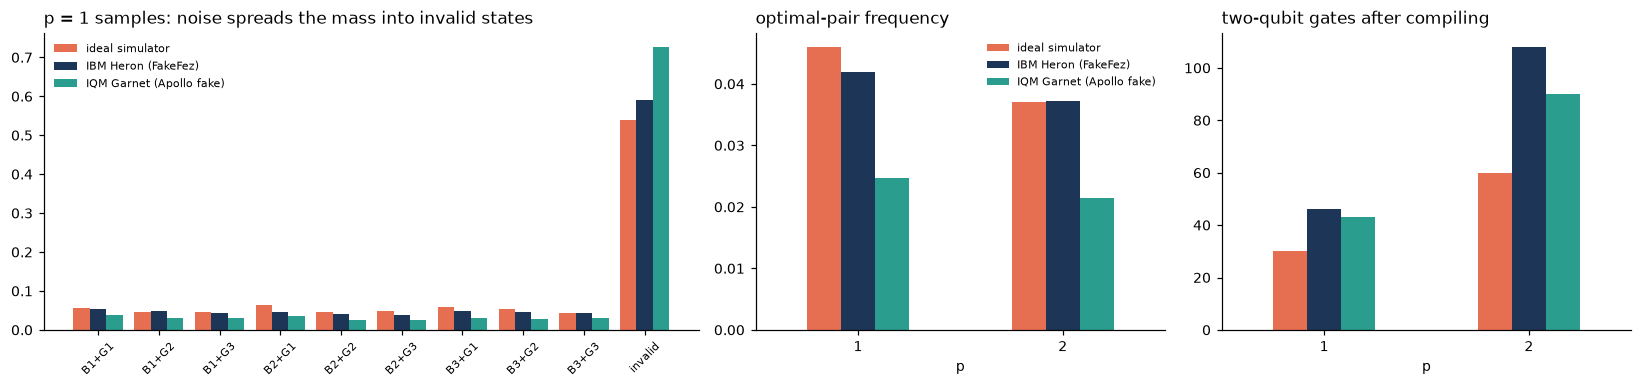

In [7]:
# The same logical circuits on IBM and IQM hardware models: fixed simulator-trained angles, compiled per device
# No IBM_QUANTUM_TOKEN / IQM_TOKEN on this machine: each vendor's published noise model (FakeFez = IBM Heron r2; IQM Apollo
# fake = the 20-qubit square lattice of IQM Garnet). With a token, `run` is the only line that changes.
from qiskit_ibm_runtime.fake_provider import FakeFez
DEV = {}
fez = FakeFez(); fsim = AerSimulator.from_backend(fez)
def ibm(c, shots, seed):
    t = transpile(c, fez, optimization_level=3, seed_transpiler=7); ibm.info = dict(depth=t.depth(), two_q=t.count_ops().get('cz', 0), qubits=6)
    return fsim.run(t, shots=shots, seed_simulator=seed).result().get_counts()
DEV['IBM Heron (FakeFez)'] = ibm
try:
    from energy import iqm_run
    def iqm(c, shots, seed):
        out = iqm_run.run(c, shots, fake='apollo', stats=True, seed=seed); iqm.info = dict(depth=out.get('depth'), two_q=out['ops'].get('cz', 0), qubits=6); return out['counts']
    DEV['IQM Garnet (Apollo fake)'] = iqm
except Exception as e: print('IQM noise model unavailable:', repr(e)[:120])
HW = {}
for p in (1, 2):
    a = QAOAAnsatz(H, reps=p); c = a.assign_parameters(angles(a, RUNS[(p, BESTRUN[p])]['theta'])); c.measure_all()
    t = transpile(c, basis_gates=['cx', 'rz', 'sx', 'x'], optimization_level=1); HW[('ideal simulator', p)] = dict(RUNS[(p, BESTRUN[p])], depth=t.depth(), two_q=t.count_ops().get('cx', 0))
    for d, run in DEV.items():
        try: t0 = time.time(); r = decode(run(c, 4000, 5)); HW[(d, p)] = dict(r, **run.info, seconds=time.time() - t0, shots=4000)
        except Exception as e: print(d, 'failed:', repr(e)[:160])
H_df = pd.DataFrame([dict(device=d, p=p, valid=v['valid'], optimal=v['opt'], best=v['best'], depth=v['depth'], two_qubit=v['two_q']) for (d, p), v in HW.items()])
print(H_df.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
devs = list(dict.fromkeys(H_df.device)); cc = {d: c for d, c in zip(devs, (CORAL, NAVY, CYAN))}
for k, d in enumerate(devs):
    s = pair_share(HW[(d, 1)]); ax[0].bar(np.arange(10) + (k - 1) * .27, list(s.values()), .27, color=cc[d], label=d)
ax[0].set_xticks(range(10), pairs + ['invalid'], rotation=45, fontsize=7.5); ax[0].legend(frameon=False, fontsize=7.5); ax[0].set_title('p = 1 samples: noise spreads the mass into invalid states', loc='left')
for k, col, t in ((1, 'optimal', 'optimal-pair frequency'), (2, 'two_qubit', 'two-qubit gates after compiling')):
    piv = H_df.pivot(index='p', columns='device', values=col)[devs]; piv.plot.bar(ax=ax[k], color=[cc[d] for d in devs], legend=k == 1); ax[k].set_title(t, loc='left'); ax[k].tick_params(axis='x', rotation=0)
ax[1].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()

,method,backend,qubits,p,valid_rate,best_profit,gap,optimal_freq,seconds,shots,cost_usd
0,Exact enumeration,CPU,NaN,NaN,NaN,295.0,0.0,NaN,0.0003,NaN,0.0000
1,Simulated annealing,CPU,6.0,NaN,1.0000,295.0,-0.0,0.1170,0.1356,1000.0,0.0000
2,Tabu search,CPU,6.0,NaN,1.0000,295.0,-0.0,1.0000,0.4813,NaN,0.0000
3,SQA (path-integral),CPU,6.0,NaN,1.0000,295.0,-0.0,0.1330,0.6130,NaN,0.0000
4,Simulated bifurcation,CPU,6.0,NaN,1.0000,295.0,-0.0,0.1210,1.1963,NaN,0.0000
5,"DCQO, 1 round",simulator (ideal),6.0,NaN,0.5790,295.0,-0.0,0.0730,0.0793,1000.0,1.7500
6,LR-QAOA p=10,simulator (ideal),6.0,10.0,0.8590,295.0,-0.0,0.1280,0.0623,1000.0,1.7500
7,CVaR-QAOA p=1,simulator (ideal),6.0,1.0,0.5660,295.0,-0.0,0.0715,0.5298,94000.0,164.5000
8,XY-QAOA p=1,simulator (ideal),6.0,1.0,1.0000,295.0,0.0,0.7258,1.4664,34000.0,58.6000
9,WS-QAOA p=1,simulator (ideal),6.0,1.0,0.6585,295.0,-0.0,0.0548,1.3880,35000.0,60.3500


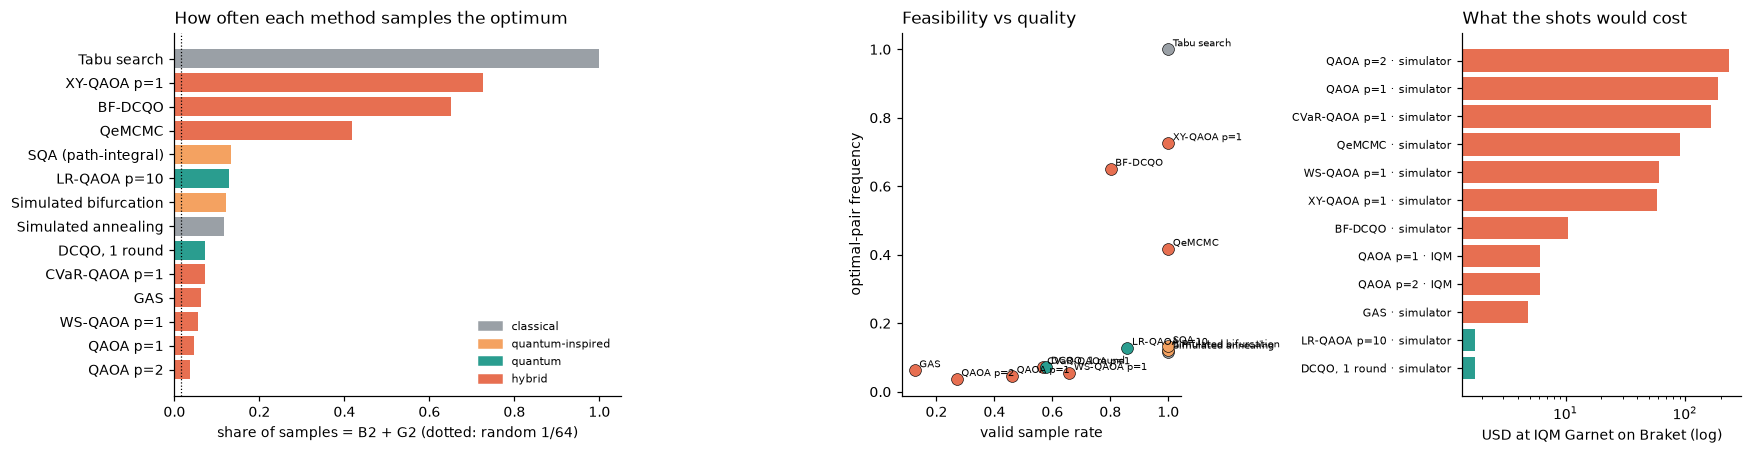

15 of 15 methods sample the exact optimum B2 + G2 (295.00 EUR): Exact enumeration, Simulated annealing, Tabu search, SQA (path-integral), Simulated bifurcation, DCQO, 1 round, LR-QAOA p=10, CVaR-QAOA p=1, XY-QAOA p=1, WS-QAOA p=1, GAS, QeMCMC, BF-DCQO, QAOA p=1, QAOA p=2


4729

In [8]:
# Every method we have on the same six-qubit QUBO: feasibility, profit, optimum frequency, time and cost
TASK, SHOT = 0.30, 0.00145      # USD a task, a shot: IQM Garnet on Amazon Braket (aws.amazon.com/braket/pricing); IBM bills QPU seconds
FAM = {'Exact enumeration': 'classical', 'Simulated annealing': 'classical', 'Tabu search': 'classical', 'SQA (path-integral)': 'quantum-inspired',
       'Simulated bifurcation': 'quantum-inspired', 'DCQO, 1 round': 'quantum', 'LR-QAOA p=10': 'quantum', 'QAOA p=1': 'hybrid', 'QAOA p=2': 'hybrid',
       'CVaR-QAOA p=1': 'hybrid', 'XY-QAOA p=1': 'hybrid', 'WS-QAOA p=1': 'hybrid', 'GAS': 'hybrid', 'QeMCMC': 'hybrid', 'BF-DCQO': 'hybrid'}
FCOL = {'classical': GREY, 'quantum-inspired': PEACH, 'quantum': CYAN, 'hybrid': CORAL}
t0 = time.time(); ex = min(K.qubo_energy(Q, x) for x in X); M = {'Exact enumeration': dict(valid_rate=np.nan, opt_rate=np.nan, best_e=ex, seconds=time.time() - t0, qubits=None, p=None)}  # all 64 states
for name, fn in [('Simulated annealing', lambda: K.anneal(TERMS, OFF, 6, ok, OPT)), ('Tabu search', lambda: K.tabu(TERMS, OFF, 6, ok, OPT)),
                 ('SQA (path-integral)', lambda: K.sqa(TERMS, OFF, 6, ok, OPT)), ('Simulated bifurcation', lambda: K.sbm(TERMS, OFF, 6, ok, OPT)),
                 ('DCQO, 1 round', lambda: K.bf_dcqo(TERMS, OFF, 6, ok, OPT, iters=1)), ('LR-QAOA p=10', lambda: K.lr_qaoa(TERMS, OFF, 6, ok, OPT)),
                 ('CVaR-QAOA p=1', lambda: K.qaoa(TERMS, OFF, 6, ok, OPT, p=1, alpha=.25, inits=3)), ('XY-QAOA p=1', lambda: K.xy_qaoa(T0, O0, GROUPS, ok, OPT)),
                 ('WS-QAOA p=1', lambda: K.ws_qaoa(TERMS, OFF, GROUPS, ok, OPT)), ('GAS', lambda: K.gas(TERMS, OFF, 6, ok, OPT)),
                 ('QeMCMC', lambda: K.qemcmc(TERMS, OFF, 6, ok, OPT)), ('BF-DCQO', lambda: K.bf_dcqo(TERMS, OFF, 6, ok, OPT))]:
    s = time.time(); M[name] = fn(); M[name]['seconds'] = time.time() - s
for p in (1, 2):
    r = RUNS[(p, BESTRUN[p])]; M[f'QAOA p={p}'] = dict(valid_rate=r['valid'], opt_rate=r['opt'], best_e=-r['best'], seconds=sum(RUNS[(p, i)]['seconds'] for i in range(3)),
                                                     shots=sum(RUNS[(p, i)]['shots'] for i in range(3)), circuit_runs=sum(RUNS[(p, i)]['evals'] + 1 for i in range(3)))
QP = {'QAOA p=1': 1, 'QAOA p=2': 2, 'CVaR-QAOA p=1': 1, 'XY-QAOA p=1': 1, 'WS-QAOA p=1': 1, 'LR-QAOA p=10': 10}
rows = []
for n, r in M.items():
    quantum = FAM[n] in ('quantum', 'hybrid'); runs, shots = r.get('circuit_runs', 0), r.get('shots', 0)
    rows.append(dict(method=n, family=FAM[n], backend='CPU' if not quantum else 'simulator (ideal)', qubits=6 if n != 'Exact enumeration' else None, p=QP.get(n),
                     valid_rate=r.get('valid_rate'), best_profit=-r['best_e'], gap=BEST + r['best_e'], optimal_freq=r.get('opt_rate'), seconds=r['seconds'],
                     shots=shots or None, cost_usd=(TASK * max(runs, 1) + SHOT * shots) if quantum and shots else 0.0))
for (d, p), v in HW.items():
    if d == 'ideal simulator': continue
    tr = RUNS[(p, BESTRUN[p])]
    rows.append(dict(method=f'QAOA p={p}', family='hybrid', backend=d, qubits=6, p=p, valid_rate=v['valid'], best_profit=v['best'], gap=BEST - v['best'], optimal_freq=v['opt'],
                     seconds=v['seconds'], shots=v['shots'], two_qubit=v['two_q'], depth=v['depth'], cost_usd=TASK + SHOT * v['shots'] if 'IQM' in d else 0.0))
S10 = pd.DataFrame(rows); pd.set_option('display.width', 200)
display(S10[['method', 'backend', 'qubits', 'p', 'valid_rate', 'best_profit', 'gap', 'optimal_freq', 'seconds', 'shots', 'cost_usd']].round(4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
sim_rows = S10[S10.backend.isin(['CPU', 'simulator (ideal)']) & (S10.method != 'Exact enumeration')].sort_values('optimal_freq')
ax[0].barh(sim_rows.method, sim_rows.optimal_freq, color=[FCOL[f] for f in sim_rows.family]); ax[0].axvline(1 / 64, color='k', ls=':', lw=.8)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c, label=f) for f, c in FCOL.items()], frameon=False, fontsize=7.5, loc='lower right'); ax[0].set_xlabel('share of samples = B2 + G2 (dotted: random 1/64)'); ax[0].set_title('How often each method samples the optimum', loc='left')
for _, r in sim_rows.iterrows(): ax[1].scatter(r.valid_rate, r.optimal_freq, s=60, color=FCOL[r.family], edgecolor='k', lw=.4); ax[1].annotate(r.method.split(' (')[0], (r.valid_rate, r.optimal_freq), fontsize=6.5, xytext=(3, 2), textcoords='offset points')
ax[1].set_xlabel('valid sample rate'); ax[1].set_ylabel('optimal-pair frequency'); ax[1].set_title('Feasibility vs quality', loc='left')
qr = S10[S10.cost_usd > 0].sort_values('cost_usd'); ax[2].barh(qr.method + ' · ' + qr.backend.str.split(' ').str[0], qr.cost_usd, color=[FCOL[f] for f in qr.family])
ax[2].set_xscale('log'); ax[2].set_xlabel('USD at IQM Garnet on Braket (log)'); ax[2].set_title('What the shots would cost', loc='left'); ax[2].tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()
found = S10[np.isclose(S10.gap, 0)].method.unique().tolist(); print(f"{len(found)} of {S10.method.nunique()} methods sample the exact optimum B2 + G2 ({BEST:.2f} EUR):", ', '.join(found))
pathlib.Path('starter_solution_results.json').write_text(S10.to_json(orient='records'))

## S10 — Evaluation
| Method | Qubits | p | Valid sample rate | Best valid expected profit | Gap to exact optimum | Optimal-pair frequency | Execution time | Total cost |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Exact enumeration | — | — | — | 295.00 | 0.00 | — | 0.00 s | $0 (CPU) |
| Simulated annealing | 6 | — | 1.000 | 295.00 | 0.00 | 0.117 | 0.14 s | $0 (CPU) |
| Tabu search | 6 | — | 1.000 | 295.00 | 0.00 | 1.000 | 0.48 s | $0 (CPU) |
| SQA (path-integral) | 6 | — | 1.000 | 295.00 | 0.00 | 0.133 | 0.61 s | $0 (CPU) |
| Simulated bifurcation | 6 | — | 1.000 | 295.00 | 0.00 | 0.121 | 1.20 s | $0 (CPU) |
| DCQO, 1 round | 6 | — | 0.579 | 295.00 | 0.00 | 0.073 | 0.08 s | $1.75 |
| LR-QAOA p=10 | 6 | 10 | 0.859 | 295.00 | 0.00 | 0.128 | 0.06 s | $1.75 |
| CVaR-QAOA p=1 | 6 | 1 | 0.566 | 295.00 | 0.00 | 0.071 | 0.53 s | $164.50 |
| XY-QAOA p=1 | 6 | 1 | 1.000 | 295.00 | 0.00 | 0.726 | 1.47 s | $58.60 |
| WS-QAOA p=1 | 6 | 1 | 0.658 | 295.00 | 0.00 | 0.055 | 1.39 s | $60.35 |
| GAS | 6 | — | 0.125 | 295.00 | 0.00 | 0.062 | 0.00 s | $4.82 |
| QeMCMC | 6 | — | 1.000 | 295.00 | 0.00 | 0.417 | 0.08 s | $90.44 |
| BF-DCQO | 6 | — | 0.801 | 295.00 | 0.00 | 0.651 | 0.33 s | $10.50 |
| QAOA p=1 | 6 | 1 | 0.461 | 295.00 | 0.00 | 0.046 | 0.78 s | $189.80 |
| QAOA p=2 | 6 | 2 | 0.270 | 295.00 | 0.00 | 0.037 | 0.96 s | $231.80 |
| QAOA p=1 · IBM Heron (FakeFez) | 6 | 1 | 0.410 | 295.00 | 0.00 | 0.042 | 2.61 s | QPU time (4,000 shots) |
| QAOA p=1 · IQM Garnet (Apollo fake) | 6 | 1 | 0.273 | 295.00 | 0.00 | 0.025 | 6.13 s | $6.10 |
| QAOA p=2 · IBM Heron (FakeFez) | 6 | 2 | 0.250 | 295.00 | 0.00 | 0.037 | 2.23 s | QPU time (4,000 shots) |
| QAOA p=2 · IQM Garnet (Apollo fake) | 6 | 2 | 0.169 | 295.00 | 0.00 | 0.021 | 5.99 s | $6.10 |

*Measured in this notebook (cell above). IBM and IQM rows are the vendors' noise models (no hardware tokens here), at the simulator-trained angles, 4,000 shots. Cost: IQM Garnet on Amazon Braket, USD 0.30 a task + 0.00145 a shot, every optimiser call counted; IBM bills QPU time instead.*

Repeat quantum rows for p = 2 and additional initialisations.

- Report profit differences in EUR, independently of penalty energy.
- Measure the valid sample rate before discarding invalid outcomes.
- Report the fraction of all samples that encode an optimal valid pair.
- Separate compilation, parameter search, device execution and queue time.
- Count all shots and optimiser calls, not just the final measurement.

This example tests model correctness and quantum solution quality. Nine plan pairs are easy to enumerate classically; the experiment does not establish a runtime or economic advantage.

For commercial payback, the relevant future metric would be additional realised profit over a strong classical method minus additional computing and operating costs.


## S11 — References
- [PennyLane: Intro to QAOA](https://pennylane.ai/demos/tutorial_qaoa_intro)
- [IBM: QAOA tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm)
- [Qiskit Optimization: Minimum Eigen Optimizer](https://qiskit-community.github.io/qiskit-optimization/tutorials/03_minimum_eigen_optimizer.html)
- [IQM: Qiskit user guide](https://docs.iqm.tech/iqm-client/user_guide_qiskit.html)
- [IQM QAOA](https://docs.iqm.tech/iqm-qaoa/)
- [QAOA theory and implementation tutorial](https://arxiv.org/abs/2301.09535)
